# Milestone 6 - Predictive Model: Weekly Revenue Forecast
**Author:** Stephen Omengo Owuor

**Business problem:** every week the chain must plan staffing and stock for each store. This notebook forecasts **next week's revenue per store**, using only information available at the end of the current week.

**Design**
- **Unit:** store x week (10 stores x 104 weeks, Monday to Sunday, 3 Jul 2023 to 29 Jun 2025). Daily store revenue is too noisy to forecast usefully (error above 35%), so weekly is the level where a forecast helps.
- **Time-aware split (no shuffling):** train 3 Jul 2023 - 30 Jun 2024, validation 1 Jul - 29 Dec 2024, test 30 Dec 2024 - 29 Jun 2025. The test set is used once, at the end.
- **Baselines:** (1) same as last week, (2) average of the last 4 weeks, (3) same week last year.
- **Models:** Ridge regression on log revenue, and gradient boosting. Settings are tuned on the validation set only.
- **Metrics:** MAE and RMSE (KES), MAPE (%), and bias (average predicted minus actual).

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlesize": 12, "axes.titleweight": "bold", "axes.grid": True, "grid.alpha": 0.25})
BLUE, ORANGE, GREY, GREEN = "#1F5FA8", "#E07B00", "#9AA5B1", "#2E8B57"
FIG = Path("figures"); FIG.mkdir(exist_ok=True)
def save(name): plt.tight_layout(); plt.savefig(FIG / f"{name}.png", bbox_inches="tight"); plt.show()

START = pd.Timestamp("2023-07-03")
d = pd.read_csv("../data/clean/sales_clean.csv", parse_dates=["date"], low_memory=False)
cal = pd.read_csv("../data/raw/calendar.csv", parse_dates=["date"])
d = d[(d.date >= START) & (d.date <= "2025-06-29")].copy()       # 104 complete Monday-Sunday weeks
cal = cal[(cal.date >= START) & (cal.date <= "2025-06-29")].copy()
d["week"] = (d.date - START).dt.days // 7
cal["week"] = (cal.date - START).dt.days // 7
print(d.week.nunique(), "weeks;", d.store_id.nunique(), "stores")

104 weeks; 10 stores


## 1. Build the weekly dataset
**Features known at forecast time**
- *History:* revenue 1, 2, 3 and 4 weeks ago, and their average. (Last week is the most recent week we would really have.)
- *Calendar of the target week (known in advance):* number of payday-window days, public-holiday days, school-opening days, December days, and the month.
- *Store:* which store.

No feature uses information from the week being forecast, so there is no leakage.

In [2]:
wk = cal.groupby("week").agg(start=("date", "min"), payday=("is_payday_window", "sum"), holiday=("is_holiday", "sum"),
        school=("is_school_opening", "sum"), dec=("date", lambda s: (s.dt.month == 12).sum()),
        month=("date", lambda s: s.iloc[3].month)).reset_index()

y = d.groupby(["store_id", "week"]).revenue.sum().unstack("week")
frames = []
for s in y.index:
    f = pd.DataFrame({"week": y.columns, "store": s, "y": y.loc[s].values})
    for k in (1, 2, 3, 4): f[f"lag_{k}"] = f.y.shift(k)
    f["mean4"] = f[["lag_1", "lag_2", "lag_3", "lag_4"]].mean(axis=1)
    f["lag_52"] = f.y.shift(52)                  # used only as a baseline
    frames.append(f)
data = pd.concat(frames).merge(wk, on="week").dropna(subset=["lag_4"]).reset_index(drop=True)

TRAIN_END, VAL_END = 51, 77                      # week numbers (0-based)
train = data[data.week <= TRAIN_END]; val = data[(data.week > TRAIN_END) & (data.week <= VAL_END)]; test = data[data.week > VAL_END]
for name, df in [("train", train), ("validation", val), ("test", test)]:
    print(f"{name:10s} weeks {df.week.min()}-{df.week.max()}  {df.start.min().date()} to {df.start.max().date()}  rows: {len(df)}")

train      weeks 4-51  2023-07-31 to 2024-06-24  rows: 480
validation weeks 52-77  2024-07-01 to 2024-12-23  rows: 260
test       weeks 78-103  2024-12-30 to 2025-06-23  rows: 260


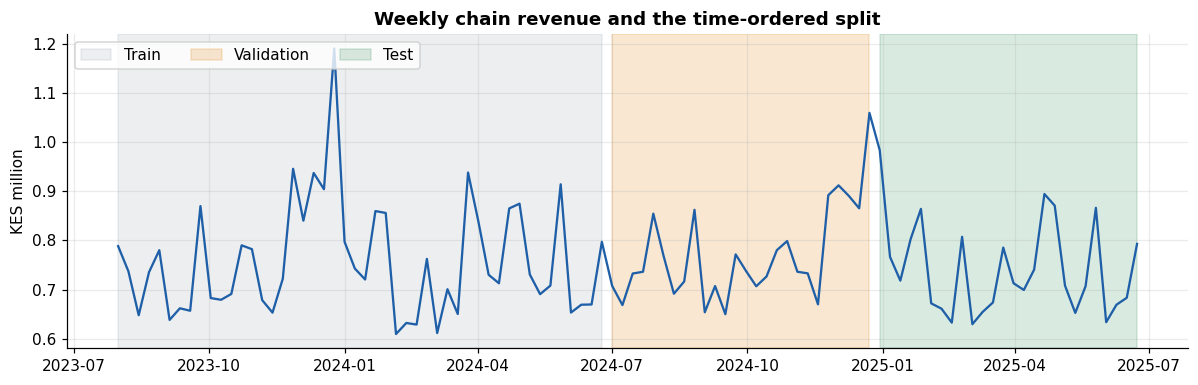

In [3]:
chain = data.groupby("start").y.sum()
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.plot(chain.index, chain / 1e6, color=BLUE)
for lo, hi, c, lab in [(train.start.min(), train.start.max(), GREY, "Train"), (val.start.min(), val.start.max(), ORANGE, "Validation"), (test.start.min(), test.start.max(), GREEN, "Test")]:
    ax.axvspan(lo, hi, color=c, alpha=0.18, label=lab)
ax.set_title("Weekly chain revenue and the time-ordered split"); ax.set_ylabel("KES million"); ax.legend(loc="upper left", ncol=3)
save("01_time_split")

## 2. Baselines and metrics

In [4]:
def metrics(actual, pred):
    actual, pred = np.asarray(actual, float), np.asarray(pred, float)
    return {"MAE": np.mean(np.abs(actual - pred)), "RMSE": np.sqrt(np.mean((actual - pred) ** 2)),
            "MAPE_%": 100 * np.mean(np.abs(actual - pred) / actual), "bias": np.mean(pred - actual)}

BASELINES = {"Baseline: same as last week": "lag_1", "Baseline: average of last 4 weeks": "mean4", "Baseline: same week last year": "lag_52"}
def baseline_table(df):
    return pd.DataFrame({name: metrics(df.y, df[col]) for name, col in BASELINES.items()}).T

print("Validation set"); baseline_table(val).round(1)

Validation set


,MAE,RMSE,MAPE_%,bias
Baseline: same as last week,12868.2,16709.7,17.8,-1007.8
Baseline: average of last 4 weeks,10239.5,13238.1,14.0,-2245.5
Baseline: same week last year,12156.1,15282.4,17.1,-720.1


## 3. Models and tuning on the validation set
**Ridge regression** predicts log revenue (revenue effects are multiplicative: a holiday adds a percentage, not a fixed amount). Predictions are converted back with a smearing correction so they are not biased low.
**Gradient boosting** (`HistGradientBoostingRegressor`) learns non-linear effects and interactions without being told.

In [5]:
NUM = ["lag_1", "lag_2", "lag_3", "lag_4", "mean4", "payday", "holiday", "school", "dec", "month"]
FEATS = NUM + ["store"]

class LogRidge:
    """Ridge on log(revenue) with a smearing correction when converting back to KES."""
    def __init__(self, alpha): self.alpha = alpha
    def fit(self, X, y):
        ct = ColumnTransformer([("num", StandardScaler(), NUM), ("store", OneHotEncoder(handle_unknown="ignore"), ["store"])])
        self.pipe = make_pipeline(ct, Ridge(alpha=self.alpha)).fit(X, np.log(y))
        self.smear = np.mean(np.exp(np.log(y) - self.pipe.predict(X)))
        return self
    def predict(self, X): return np.exp(self.pipe.predict(X)) * self.smear

class Boosted:
    def __init__(self, lr, leaves): self.lr, self.leaves = lr, leaves
    def fit(self, X, y):
        self.codes = {s: i for i, s in enumerate(sorted(X.store.unique()))}
        self.m = HistGradientBoostingRegressor(learning_rate=self.lr, max_leaf_nodes=self.leaves, max_iter=200, min_samples_leaf=10,
                                               l2_regularization=1.0, random_state=0).fit(self._x(X), y)
        return self
    def _x(self, X): return X[NUM].assign(store=X.store.map(self.codes))
    def predict(self, X): return self.m.predict(self._x(X))

candidates = {f"Ridge (alpha={a})": (lambda a=a: LogRidge(a)) for a in (0.1, 1, 10, 30)}
candidates.update({f"Boosting (lr={lr}, leaves={lv})": (lambda lr=lr, lv=lv: Boosted(lr, lv)) for lr in (0.05, 0.1) for lv in (4, 8)})

rows = {}
for name, make in candidates.items():
    rows[name] = metrics(val.y, make().fit(train[FEATS], train.y).predict(val[FEATS]))
tuning = pd.DataFrame(rows).T.sort_values("MAE")
best_name = tuning.index[0]
print("Best on validation:", best_name)
tuning.round(1)

Best on validation: Ridge (alpha=0.1)


,MAE,RMSE,MAPE_%,bias
Ridge (alpha=0.1),7867.6,9880.9,11.4,-646.8
Ridge (alpha=1),8018.5,10056.6,11.5,-552.9
"Boosting (lr=0.05, leaves=4)",8062.4,10243.9,11.6,-756.6
"Boosting (lr=0.05, leaves=8)",8149.4,10408.6,11.6,-934.6
"Boosting (lr=0.1, leaves=4)",8194.8,10399.5,11.7,-938.6
"Boosting (lr=0.1, leaves=8)",8290.4,10604.5,11.7,-1117.5
Ridge (alpha=10),8773.5,11154.3,12.5,-169.8
Ridge (alpha=30),9129.4,11633.3,13.0,-139.6


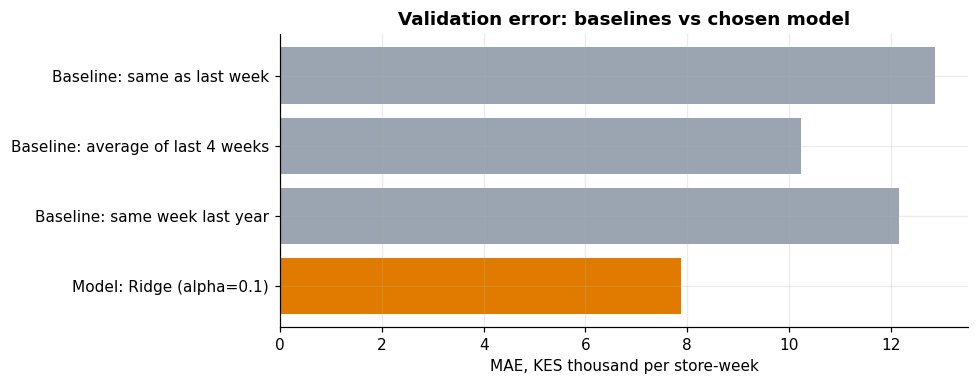

,MAE,RMSE,MAPE_%,bias
Baseline: same as last week,12868.2,16709.7,17.8,-1007.8
Baseline: average of last 4 weeks,10239.5,13238.1,14.0,-2245.5
Baseline: same week last year,12156.1,15282.4,17.1,-720.1
Model: Ridge (alpha=0.1),7867.6,9880.9,11.4,-646.8


In [6]:
comparison = pd.concat([baseline_table(val), tuning.loc[[best_name]].rename(index=lambda s: "Model: " + s)])
fig, ax = plt.subplots(figsize=(9, 3.6))
colors = [GREY] * 3 + [ORANGE]
ax.barh(comparison.index[::-1], comparison.MAE[::-1] / 1e3, color=colors[::-1]); ax.set_xlabel("MAE, KES thousand per store-week")
ax.set_title("Validation error: baselines vs chosen model")
save("02_validation_comparison")
comparison.round(1)

## 4. Final test (used once)
The chosen model is refitted on train + validation (all weeks before the test period) and evaluated on the untouched test weeks. No settings are changed after seeing these numbers.

In [7]:
make_best = candidates[best_name]
final = make_best().fit(pd.concat([train, val])[FEATS], pd.concat([train, val]).y)
test = test.assign(pred=final.predict(test[FEATS]))

best_base = min(BASELINES, key=lambda n: metrics(val.y, val[BASELINES[n]])["MAE"])   # best baseline chosen on validation
final_table = pd.concat([baseline_table(test), pd.DataFrame({"Model: " + best_name: metrics(test.y, test.pred)}).T])
print("Test set (26 weeks x 10 stores)"); print(final_table.round(1))
gain = 1 - final_table.loc["Model: " + best_name, "MAE"] / final_table.loc[best_base, "MAE"]
print(f"\nBest baseline (chosen on validation): {best_base}")
print(f"Model MAE is {gain:.0%} lower than that baseline.")
final_table.round(1).to_csv("model_comparison.csv")
test[["store", "start", "y", "pred", "lag_1", "mean4", "lag_52"]].to_csv("test_predictions.csv", index=False)

Test set (26 weeks x 10 stores)
                                       MAE     RMSE  MAPE_%    bias
Baseline: same as last week        14468.3  18167.1    20.9  1023.9
Baseline: average of last 4 weeks  11848.2  15004.7    17.3  2241.3
Baseline: same week last year      11197.0  14689.4    16.1   315.4
Model: Ridge (alpha=0.1)            8129.8  10291.2    12.0   267.8

Best baseline (chosen on validation): Baseline: average of last 4 weeks
Model MAE is 31% lower than that baseline.


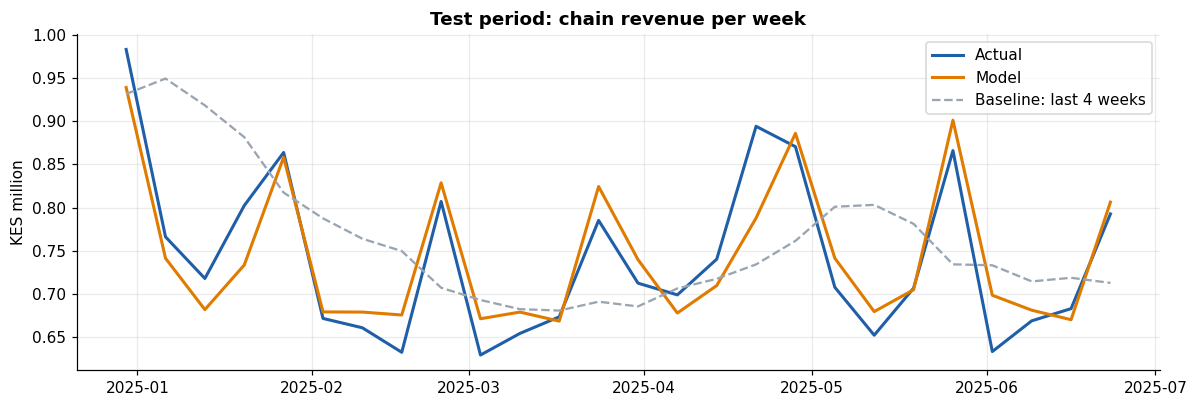

In [8]:
top = test.groupby("start")[["y", "pred", "mean4"]].sum()
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(top.index, top.y / 1e6, color=BLUE, lw=2, label="Actual"); ax.plot(top.index, top.pred / 1e6, color=ORANGE, lw=2, label="Model")
ax.plot(top.index, top.mean4 / 1e6, color=GREY, lw=1.5, ls="--", label="Baseline: last 4 weeks")
ax.set_title("Test period: chain revenue per week"); ax.set_ylabel("KES million"); ax.legend()
save("03_test_forecast")

## 5. Is the improvement stable? Rolling-origin backtest
A single test period could be lucky. Here the model is refitted and tested on four consecutive 13-week windows, always training only on earlier weeks.

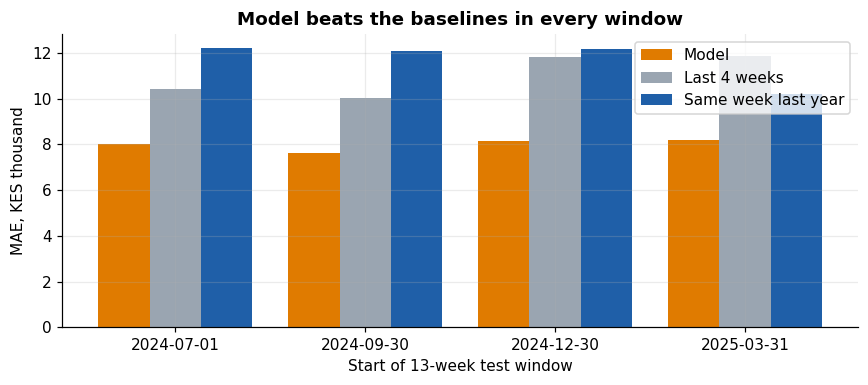

,test weeks,from,model MAE,last-4-weeks MAE,last-year MAE,model vs best baseline
0,52-64,2024-07-01,8012.96,10436.89,12218.23,0.23
1,65-77,2024-09-30,7643.57,10042.07,12094.06,0.24
2,78-90,2024-12-30,8151.30,11837.59,12189.18,0.31
3,91-103,2025-03-31,8189.02,11858.85,10204.84,0.20


In [9]:
folds = [(52, 64), (65, 77), (78, 90), (91, 103)]
bt = []
for lo, hi in folds:
    tr_, te_ = data[data.week < lo], data[(data.week >= lo) & (data.week <= hi)]
    p = make_best().fit(tr_[FEATS], tr_.y).predict(te_[FEATS])
    bt.append({"test weeks": f"{lo}-{hi}", "from": te_.start.min().date(), "model MAE": metrics(te_.y, p)["MAE"],
               "last-4-weeks MAE": metrics(te_.y, te_.mean4)["MAE"], "last-year MAE": metrics(te_.y, te_.lag_52)["MAE"]})
bt = pd.DataFrame(bt); bt["model vs best baseline"] = 1 - bt["model MAE"] / bt[["last-4-weeks MAE", "last-year MAE"]].min(axis=1)
fig, ax = plt.subplots(figsize=(8, 3.6)); w = 0.27; xs = np.arange(len(bt))
ax.bar(xs - w, bt["model MAE"] / 1e3, w, color=ORANGE, label="Model"); ax.bar(xs, bt["last-4-weeks MAE"] / 1e3, w, color=GREY, label="Last 4 weeks"); ax.bar(xs + w, bt["last-year MAE"] / 1e3, w, color=BLUE, label="Same week last year")
ax.set_xticks(xs); ax.set_xticklabels([str(f) for f in bt["from"]]); ax.set_xlabel("Start of 13-week test window"); ax.set_ylabel("MAE, KES thousand"); ax.legend()
ax.set_title("Model beats the baselines in every window")
save("04_backtest")
bt.round(2)

## 6. What does the model get wrong?

           MAE  MAPE_%    bias  baseline MAPE_%
store                                          
S01    10165.7     8.8  2788.2             13.9
S02     8691.4     8.1 -2625.8             15.5
S03     9270.9    10.3   236.6             17.2
S04     9924.2    13.5  -239.3             19.5
S05     6818.7    10.0  4294.6             14.7
S06     9306.7    13.5  1148.0             16.7
S07     6998.4    12.8  -457.1             17.6
S08     6940.8    13.1  -473.5             20.0
S09     6804.4    14.1 -1855.3             19.9
S10     6377.1    16.0  -138.5             18.1


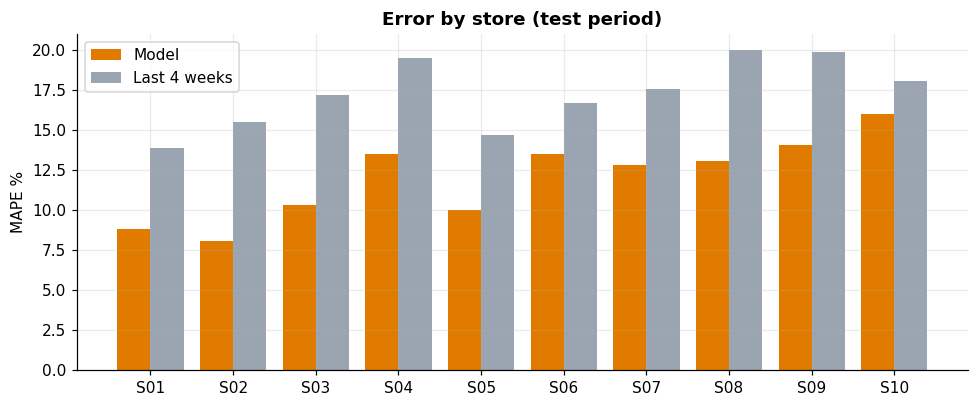

In [10]:
test["error"] = test.pred - test.y; test["pct_error"] = 100 * test.error / test.y

by_store = test.groupby("store").apply(lambda g: pd.Series({"MAE": g.error.abs().mean(), "MAPE_%": g.pct_error.abs().mean(),
              "bias": g.error.mean(), "baseline MAPE_%": (100 * (g.mean4 - g.y).abs() / g.y).mean()}), include_groups=False).round(1)
print(by_store)

fig, ax = plt.subplots(figsize=(9, 3.8)); xs = np.arange(len(by_store))
ax.bar(xs - 0.2, by_store["MAPE_%"], 0.4, color=ORANGE, label="Model"); ax.bar(xs + 0.2, by_store["baseline MAPE_%"], 0.4, color=GREY, label="Last 4 weeks")
ax.set_xticks(xs); ax.set_xticklabels(by_store.index); ax.set_ylabel("MAPE %"); ax.set_title("Error by store (test period)"); ax.legend()
save("05_error_by_store")

Average % error (predicted minus actual) by week type:
                            mean  count
holiday_week                           
ordinary week                3.4    210
week with a public holiday  -1.8     50

Worst 8 forecasts:
store      start        y     pred  pct_error  holiday  payday
  S04 2025-03-24 120276.0  86944.0      -28.0        0       6
  S08 2025-05-19  80902.0  52599.0      -35.0        0       1
  S02 2025-04-28 148242.0 120142.0      -19.0        1       5
  S01 2025-06-02  89898.0 115401.0       28.0        0       1
  S01 2025-03-10 136615.0 111544.0      -18.0        0       0
  S04 2025-05-05  53860.0  78449.0       46.0        0       0
  S02 2024-12-30 152634.0 129193.0      -15.0        1       4
  S03 2025-06-09 107378.0  84871.0      -21.0        0       0


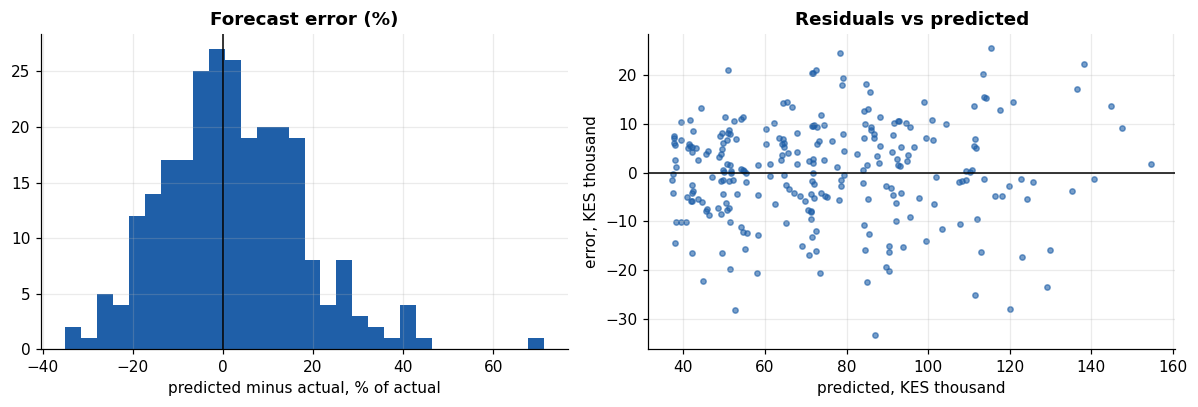

In [11]:
test["holiday_week"] = test.holiday > 0
test["payday_heavy"] = test.payday >= 5
print("Average % error (predicted minus actual) by week type:")
print(test.groupby("holiday_week").pct_error.agg(["mean", "count"]).round(1).rename(index={True: "week with a public holiday", False: "ordinary week"}))
print("\nWorst 8 forecasts:")
worst = test.reindex(test.error.abs().sort_values(ascending=False).index).head(8)[["store", "start", "y", "pred", "pct_error", "holiday", "payday"]]
worst = worst.assign(start=worst.start.dt.date, y=worst.y.round(0), pred=worst.pred.round(0), pct_error=worst.pct_error.round(0))
print(worst.to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].hist(test.pct_error, bins=30, color=BLUE); ax[0].axvline(0, color="k", lw=1); ax[0].set_title("Forecast error (%)"); ax[0].set_xlabel("predicted minus actual, % of actual")
ax[1].scatter(test.pred / 1e3, test.error / 1e3, s=12, color=BLUE, alpha=0.6); ax[1].axhline(0, color="k", lw=1)
ax[1].set_title("Residuals vs predicted"); ax[1].set_xlabel("predicted, KES thousand"); ax[1].set_ylabel("error, KES thousand")
save("06_residuals")

**How much error is unavoidable?** Even a perfect model cannot predict how many customers walk in or how much each spends. From the basket data, a store-week with *n* baskets has a revenue coefficient of variation of about sqrt((1 + (sd/mean)^2) / n). Multiplying by 0.8 turns that into an expected absolute % error.

In [12]:
tx = d.groupby(["store_id", "week", "transaction_id"]).revenue.sum().reset_index()
sw = tx.groupby(["store_id", "week"]).revenue.agg(n="count", mean="mean", sd="std")
sw["cv"] = np.sqrt((1 + (sw.sd / sw["mean"]) ** 2) / sw.n)
floor = 100 * 0.8 * sw.loc[sw.index.get_level_values("week") > VAL_END, "cv"].mean()
print(f"Approximate unavoidable error in the test period: about {floor:.1f}% MAPE")
print(f"Model MAPE: {test.pct_error.abs().mean():.1f}%  ->  about {test.pct_error.abs().mean() - floor:.1f} points above the noise floor")

Approximate unavoidable error in the test period: about 11.2% MAPE
Model MAPE: 12.0%  ->  about 0.8 points above the noise floor


## 7. What drives the forecast?

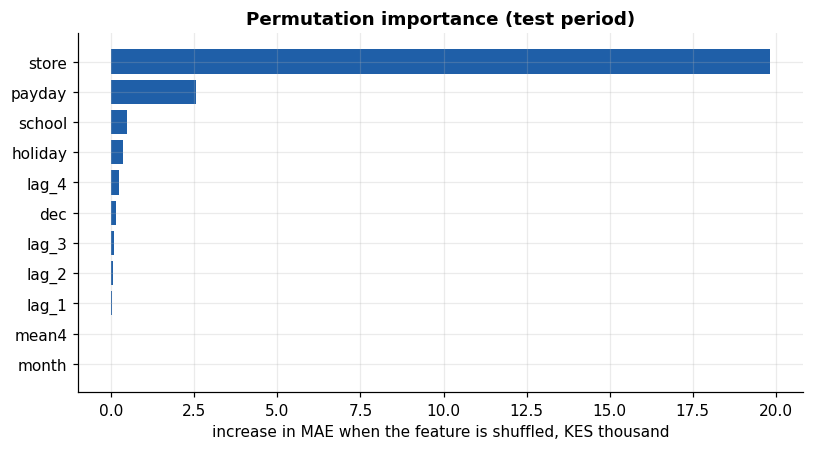

store      19825.0
payday      2549.0
school       474.0
holiday      347.0
lag_4        235.0
dec          151.0
lag_3         80.0
lag_2         57.0
lag_1         38.0
mean4          7.0
month        -10.0
dtype: float64

In [13]:
# Permutation importance: shuffle one feature at a time and see how much the error grows
rng = np.random.default_rng(0)
base_mae = np.mean(np.abs(test.y - final.predict(test[FEATS])))
imp = {}
for col in FEATS:
    gains = []
    for _ in range(20):
        shuffled = test[FEATS].copy(); shuffled[col] = rng.permutation(shuffled[col].values)
        gains.append(np.mean(np.abs(test.y - final.predict(shuffled))) - base_mae)
    imp[col] = np.mean(gains)
imp = pd.Series(imp).sort_values()
fig, ax = plt.subplots(figsize=(7.5, 4.2)); ax.barh(imp.index, imp.values / 1e3, color=BLUE)
ax.set_title("Permutation importance (test period)"); ax.set_xlabel("increase in MAE when the feature is shuffled, KES thousand")
save("07_importance")
imp.sort_values(ascending=False).round(0)

## Conclusions in plain language
Write your own conclusions after reading the outputs above:

1. Which model won on validation, and how does it compare with the baselines on the test set (numbers)?
2. Is the improvement stable across the four backtest windows?
3. What does the model get wrong (stores, holiday weeks, the worst forecasts)?
4. How close is it to the unavoidable noise level?
5. What should the business do with it, and what are the limits?